# Unsupervised Learning Analysis: World Development Indicators
**Author:** Gurkeerat Jawanda  \
**Date:** November 2026  


In [97]:
import urllib.request
import zipfile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [55]:
os.makedirs("data", exist_ok=True)

url = "https://databank.worldbank.org/data/download/WDI_CSV.zip"
zip_path = "data/WDI_CSV.zip"

print("Downloading...")
urllib.request.urlretrieve(url, zip_path)

print("Extracting...")
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("data/")
    print("Files extracted:", z.namelist())

Downloading...
Extracting...
Files extracted: ['WDICSV.csv', 'WDICountry.csv', 'WDISeries.csv', 'WDIcountry-series.csv', 'WDIfootnote.csv', 'WDIseries-time.csv']


In [56]:
df = pd.read_csv("data/WDICSV.csv")

In [57]:
print(df.shape)
df.head()

(398468, 70)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,18.471500,18.822373,19.302882,19.770426,20.120927,20.440680,20.817895,21.161010,21.532841,NaN
1,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.682625,7.953281,8.528101,8.878267,9.050266,9.111884,9.285654,9.403676,9.687390,NaN
2,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,39.163151,39.206303,39.406216,39.569413,39.958115,40.025590,40.203585,40.728295,41.118943,NaN
3,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.859598,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN
4,Africa Eastern and Southern,AFE,"Access to electricity, rural (% of rural popul...",EG.ELC.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,24.584906,25.375037,26.941984,28.983183,30.909991,32.709837,33.998179,35.240236,36.080572,NaN


#### We need to reshape it — pivot so each row is one country, each column is one indicator, using a single year (we’ll use 2019).

In [58]:
print("Total unique countries:", df["Country Name"].nunique())
print("Total unique indicators:", df["Indicator Name"].nunique())
print("\nSample indicators:")
for ind in df["Indicator Name"].sample(20, random_state=42).tolist():
    print(ind)

Total unique countries: 266
Total unique indicators: 1498

Sample indicators:
Educational attainment, at least completed post-secondary, population 25+, female (%) (cumulative)
Women who believe a husband is justified in beating his wife when she burns the food (%)
Share of youth not in education, employment or training, male (% of male youth population)  (modeled ILO estimate)
Women participating in the three decisions (own health care, major household purchases, and visiting family) (% of women age 15-49)
Annual freshwater withdrawals, industry (% of total freshwater withdrawal)
Survey mean consumption or income per capita, total population (2021 PPP $ per day)
Progression to secondary school, male (%)
Computer, communications and other services (% of commercial service imports)
Firms exporting directly at least 10% of sales (% of firms)
Net official flows from UN agencies, IFAD (current US$)
Fixed telephone subscriptions
Electricity production from nuclear sources (% of total)
Propo

In [59]:
INDICATORS = {
    "NY.GDP.PCAP.CD":        "gdp_per_capita",
    "SP.DYN.LE00.IN":        "life_expectancy",
    "SE.ADT.LITR.ZS":        "adult_literacy_rate",
    "SH.DYN.MORT":           "child_mortality",
    "SP.POP.GROW":           "population_growth",
    "EG.ELC.ACCS.ZS":        "electricity_access",
    "IT.NET.USER.ZS":        "internet_users",
    "SH.XPD.CHEX.GD.ZS":    "health_expenditure_pct_gdp",
    "SE.XPD.TOTL.GD.ZS":    "education_expenditure_pct_gdp",
    "EN.ATM.CO2E.PC":        "co2_emissions_per_capita",
    "SL.UEM.TOTL.ZS":        "unemployment_rate",
    "FP.CPI.TOTL.ZG":        "inflation_rate",
    "SP.URB.TOTL.IN.ZS":     "urban_population_pct",
    "GC.TAX.TOTL.GD.ZS":     "tax_revenue_pct_gdp",
    "BX.KLT.DINV.WD.GD.ZS":  "fdi_pct_gdp",
}
YEAR = "2019"

In [60]:
df["Indicator Code"].nunique()

1498

In [61]:
subset = df[df["Indicator Code"].isin(INDICATORS.keys())][
    ["Country Code", "Country Name", "Indicator Code", YEAR]
].copy()

pivot = subset.pivot_table(
    index=["Country Code", "Country Name"],
    columns="Indicator Code",
    values=YEAR
).reset_index()

pivot.rename(columns=INDICATORS, inplace=True)
pivot.columns.name = None

print(pivot.shape)
pivot.head(3)

(265, 16)


,Country Code,Country Name,fdi_pct_gdp,electricity_access,inflation_rate,tax_revenue_pct_gdp,internet_users,gdp_per_capita,adult_literacy_rate,education_expenditure_pct_gdp,child_mortality,health_expenditure_pct_gdp,unemployment_rate,life_expectancy,population_growth,urban_population_pct
0,ABW,Aruba,-2.247204,100.000000,4.257462,NaN,NaN,30654.485124,NaN,4.435037,NaN,NaN,NaN,76.019000,0.270505,62.288276
1,AFE,Africa Eastern and Southern,1.471924,44.390861,4.102851,17.833362,21.6,1508.031525,72.800003,4.511410,61.491636,5.754125,7.459106,63.857261,2.721681,36.097331
2,AFG,Afghanistan,0.124496,97.700000,2.302373,NaN,17.6,496.602504,NaN,NaN,62.700000,14.831320,11.187000,62.941000,2.984389,25.143726


In [62]:
countries_meta = pd.read_csv("data/WDICountry.csv")
real_countries = countries_meta[countries_meta["Region"].notna()]["Country Code"].tolist()
pivot = pivot[pivot["Country Code"].isin(real_countries)].reset_index(drop=True)
print("Countries after filtering aggregates:", len(pivot))

Countries after filtering aggregates: 217


In [63]:
missing = (pivot.isnull().sum() / len(pivot) * 100).round(1)
print("\nMissing % per indicator:")
print(missing.sort_values(ascending=False))


Missing % per indicator:
adult_literacy_rate              74.2
tax_revenue_pct_gdp              36.4
education_expenditure_pct_gdp    23.0
inflation_rate                   15.2
unemployment_rate                13.8
internet_users                   12.9
health_expenditure_pct_gdp       11.1
fdi_pct_gdp                      10.1
child_mortality                   9.7
gdp_per_capita                    2.8
electricity_access                0.9
Country Code                      0.0
Country Name                      0.0
life_expectancy                   0.0
population_growth                 0.0
urban_population_pct              0.0
dtype: float64


In [64]:
cols_to_drop = ["adult_literacy_rate", "tax_revenue_pct_gdp", "education_expenditure_pct_gdp"]
pivot.drop(columns=cols_to_drop, inplace=True)

In [65]:
feature_cols = [c for c in pivot.columns if c not in ["Country Code", "Country Name"]]
pivot[feature_cols] = pivot[feature_cols].fillna(pivot[feature_cols].median())

In [66]:
print("Remaining NaNs:", pivot[feature_cols].isnull().sum().sum())
print("Final shape:", pivot.shape)
print("Features:", feature_cols)

Remaining NaNs: 0
Final shape: (217, 13)
Features: ['fdi_pct_gdp', 'electricity_access', 'inflation_rate', 'internet_users', 'gdp_per_capita', 'child_mortality', 'health_expenditure_pct_gdp', 'unemployment_rate', 'life_expectancy', 'population_growth', 'urban_population_pct']


---

## 1. Dataset Description

The dataset used in this analysis is the **World Development Indicators (WDI)**, published annually by the World Bank. It is the World Bank's primary collection of internationally comparable development statistics, compiled from officially recognised international sources and made publicly available under a Creative Commons Attribution 4.0 licence.

The raw dataset contains 398,468 rows and 70 columns, structured in a long format where each row represents one country-indicator pair, with one column per year from 1960 to 2022. After filtering to 217 sovereign nations (removing regional and income-group aggregates), selecting 2019 as the reference year to avoid COVID-19 disruptions, and retaining 11 well-populated indicators, the final analytical dataset contains **217 countries × 11 features**.

The 11 indicators span five development dimensions:

| Dimension | Indicators |
|---|---|
| Economic | GDP per capita, FDI as % of GDP, Inflation rate |
| Health | Life expectancy, Child mortality, Health expenditure % GDP |
| Infrastructure | Electricity access, Internet users, Urban population % |
| Labour | Unemployment rate |
| Demographic | Population growth |

Three indicators were dropped due to excessive missingness: adult literacy rate (74.2%), tax revenue % GDP (36.4%), and education expenditure % GDP (23.0%). Remaining missing values (all under 16%) were imputed using column medians to preserve country coverage without introducing distributional bias.

**Analytical objective:** To identify natural groupings of countries based on their development profiles using unsupervised learning, without relying on pre-existing income classifications, and to understand the underlying structure of global development data.

In [71]:
scaler = StandardScaler()
x = scaler.fit_transform(pivot[feature_cols])
print("Scaled array shape:", x.shape)
print("Mean of each feature (should be ~0):", x.mean(axis=0).round(2))
print("Std of each feature (should be ~1):", x.std(axis=0).round(2))

Scaled array shape: (217, 11)
Mean of each feature (should be ~0): [-0. -0.  0. -0.  0.  0. -0. -0. -0.  0.  0.]
Std of each feature (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


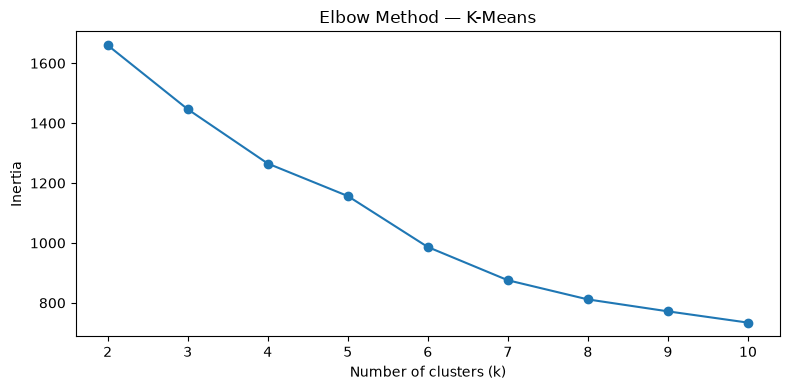

In [77]:
inertias = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(x)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method — K-Means")
plt.xticks(k_range)
plt.tight_layout()
plt.savefig("elbow.png", dpi=150)
plt.show()

In [80]:
results = {}
for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(x)
    sil = silhouette_score(x, labels)
    results[k] = {"model": km, "labels": labels, "silhouette": sil}
    print(f"k={k} | Inertia: {km.inertia_:.1f} | Silhouette: {sil:.4f}")

k=3 | Inertia: 1446.5 | Silhouette: 0.2399
k=4 | Inertia: 1265.2 | Silhouette: 0.2247
k=5 | Inertia: 1156.7 | Silhouette: 0.1946


#### Strictly by silhouette, k=3 wins. But these scores are all in the 0.19–0.24 range which is modest — this is expected for real-world country data, countries don’t fall into perfectly clean clusters.

In [81]:
pivot["cluster"] = results[3]["labels"]

profile = pivot.groupby("cluster")[feature_cols].mean().round(2)
print(profile.T)

print("\nCluster sizes:")
print(pivot["cluster"].value_counts().sort_index())

cluster                            0        1         2
fdi_pct_gdp                    20.85     1.74      4.53
electricity_access            100.00    48.17     96.74
inflation_rate                  1.62    12.51      3.43
internet_users                 86.60    23.41     65.91
gdp_per_capita              56678.05  1850.80  10193.00
child_mortality                 7.13    70.23     16.67
health_expenditure_pct_gdp      7.77     5.36      6.33
unemployment_rate               5.00     7.24      7.76
life_expectancy                81.62    62.10     74.09
population_growth               0.96     2.45      0.54
urban_population_pct           85.13    39.08     61.29

Cluster sizes:
cluster
0     49
1     50
2    118
Name: count, dtype: int64


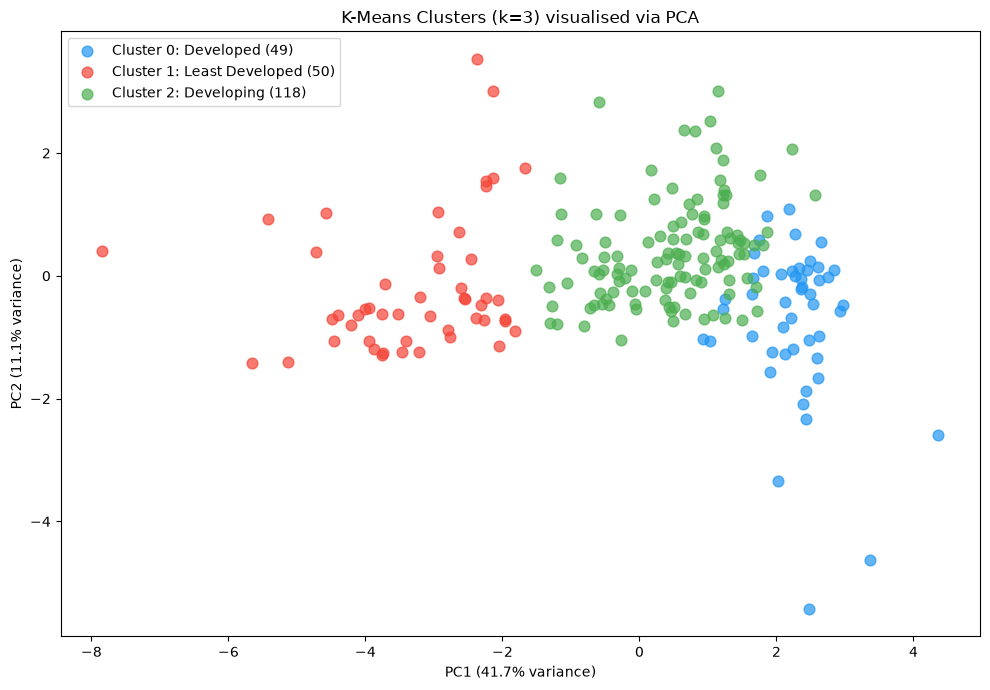

In [83]:
pca_viz = PCA(n_components=2, random_state=42)
X_2d = pca_viz.fit_transform(x)

plt.figure(figsize=(10, 7))
colors = {0: "#2196F3", 1: "#F44336", 2: "#4CAF50"}
labels_map = {0: "Cluster 0: Developed (49)", 1: "Cluster 1: Least Developed (50)", 2: "Cluster 2: Developing (118)"}

for cluster_id in [0, 1, 2]:
    mask = pivot["cluster"] == cluster_id
    plt.scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        c=colors[cluster_id],
        label=labels_map[cluster_id],
        alpha=0.7, s=60
    )

plt.xlabel(f"PC1 ({pca_viz.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_viz.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means Clusters (k=3) visualised via PCA")
plt.legend()
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=150)
plt.show()

In [86]:
dbscan_results = {}

for eps, min_samples in [(1.5, 5), (2.0, 5), (2.0, 3)]:
    db = DBSCAN(eps=eps, min_samples=min_samples)
    labels = db.fit_predict(x)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    if n_clusters > 1:
        sil = silhouette_score(x, labels)
    else:
        sil = None
    dbscan_results[(eps, min_samples)] = labels
    print(f"eps={eps}, min_samples={min_samples} | Clusters: {n_clusters} | Noise points: {n_noise} | Silhouette: {sil}")

eps=1.5, min_samples=5 | Clusters: 1 | Noise points: 58 | Silhouette: None
eps=2.0, min_samples=5 | Clusters: 1 | Noise points: 22 | Silhouette: None
eps=2.0, min_samples=3 | Clusters: 1 | Noise points: 19 | Silhouette: None


DBSCAN is finding only 1 cluster in every configuration. This means the country data doesn’t have the kind of structure DBSCAN is looking for — it doesn’t have dense islands separated by empty space. Instead the data is one continuous gradient from least developed to most developed, with no clear gaps between groups. That’s why K-Means works better here — it can partition a continuous space, while DBSCAN needs natural density gaps to find multiple clusters.

In [89]:

for eps in [3.0, 4.0, 5.0]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(x)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    print(f"eps={eps} | Clusters: {n_clusters} | Noise: {n_noise}")


db_final = DBSCAN(eps=2.0, min_samples=5)
db_labels = db_final.fit_predict(x)
outliers = pivot[db_labels == -1][["Country Name", "gdp_per_capita", "life_expectancy", "child_mortality"]]
print("\nOutlier countries flagged by DBSCAN:")
print(outliers.to_string(index=False))

eps=3.0 | Clusters: 1 | Noise: 10
eps=4.0 | Clusters: 1 | Noise: 6
eps=5.0 | Clusters: 1 | Noise: 5

Outlier countries flagged by DBSCAN:
             Country Name  gdp_per_capita  life_expectancy  child_mortality
              Afghanistan      496.602504        62.941000             62.7
                Argentina     9955.974787        76.847000             10.5
 Central African Republic      449.228468        31.530000            254.7
              Congo, Rep.     2488.424667        63.152000             52.2
                   Cyprus    29227.167969        81.454000              3.0
    Micronesia, Fed. Sts.     3581.726846        66.196000             26.4
            Liechtenstein   166907.839305        84.160976             15.8
                  Lesotho     1082.057068        55.249000             68.1
               Luxembourg   112696.649060        82.639024              2.4
 St. Martin (French part)    19033.064963        80.078000             15.8
                   Monaco 

Liechtenstein (166k GDP) and Monaco (193k GDP) — extreme outliers on the high end, tiny wealthy microstates \
Luxembourg ($112k GDP) — same story \
Central African Republic (child mortality 254!) — extreme outlier on the low end\
Somalia (child mortality 118) — similarly extreme\
Argentina — interesting one, middle income but flagged because its inflation and economic instability make it anomalous\
North Korea — anomalous because it’s mid-income GDP but socially isolated, unusual profile

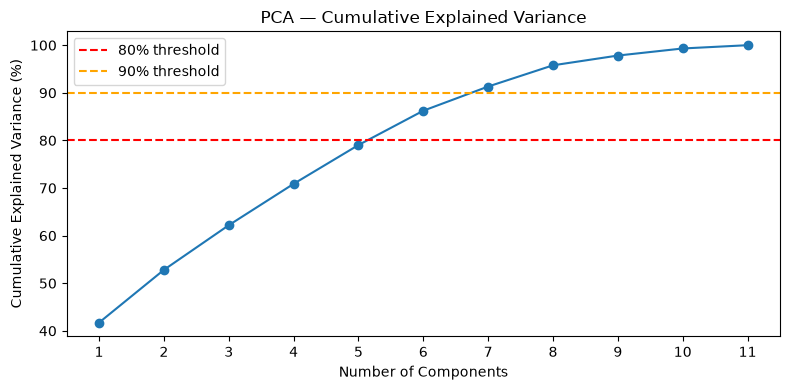

PC1: 41.7%
PC2: 52.8%
PC3: 62.2%
PC4: 70.9%
PC5: 79.0%
PC6: 86.2%
PC7: 91.3%
PC8: 95.8%
PC9: 97.8%
PC10: 99.3%
PC11: 100.0%


In [92]:
pca_full = PCA(random_state=42)
pca_full.fit(x)

cumvar = np.cumsum(pca_full.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumvar)+1), cumvar, marker="o")
plt.axhline(80, color="red", linestyle="--", label="80% threshold")
plt.axhline(90, color="orange", linestyle="--", label="90% threshold")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.xticks(range(1, len(cumvar)+1))
plt.tight_layout()
plt.savefig("pca_variance.png", dpi=150)
plt.show()

for i, v in enumerate(cumvar):
    print(f"PC{i+1}: {v:.1f}%")

In [94]:
pca_3 = PCA(n_components=3, random_state=42)
pca_3.fit(x)

loadings = pd.DataFrame(
    pca_3.components_.T,
    index=feature_cols,
    columns=["PC1", "PC2", "PC3"]
).round(3)

print("PCA Loadings (contribution of each feature to each component):")
print(loadings.sort_values("PC1", ascending=False))
print(f"\nVariance explained: PC1={pca_3.explained_variance_ratio_[0]*100:.1f}%, PC2={pca_3.explained_variance_ratio_[1]*100:.1f}%, PC3={pca_3.explained_variance_ratio_[2]*100:.1f}%")

PCA Loadings (contribution of each feature to each component):
                              PC1    PC2    PC3
internet_users              0.430 -0.007  0.061
life_expectancy             0.430 -0.128 -0.013
electricity_access          0.405  0.099 -0.091
urban_population_pct        0.332  0.037  0.180
gdp_per_capita              0.282 -0.362  0.113
health_expenditure_pct_gdp  0.143  0.398  0.206
fdi_pct_gdp                 0.071 -0.446  0.640
unemployment_rate          -0.025  0.591  0.536
inflation_rate             -0.113  0.096  0.341
population_growth          -0.267 -0.353  0.290
child_mortality            -0.408 -0.035  0.050

Variance explained: PC1=41.7%, PC2=11.1%, PC3=9.4%


## 2. Analytical Approach and Model Development

### Data Preprocessing
The raw WDI data was reshaped from long format (one row per country-indicator pair) to wide format (one row per country, one column per indicator) using a pivot operation. Regional aggregates were removed using the WDICountry metadata file, which identifies sovereign nations by the presence of a non-null Region field. Features were standardised using StandardScaler (zero mean, unit variance) prior to all modelling, since clustering algorithms are sensitive to feature scale.

### Model Variations

Three unsupervised learning approaches were applied, each with multiple configurations:

**Model 1 — K-Means Clustering (3 variations)**

The elbow method was used to identify candidate values of k by plotting inertia against k=2 through k=10. The curve showed a clear bend between k=3 and k=5. Three configurations were evaluated:

| Configuration | Inertia | Silhouette Score |
|---|---|---|
| K-Means k=3 | 1446.5 | 0.2399 |
| K-Means k=4 | 1265.2 | 0.2247 |
| K-Means k=5 | 1156.7 | 0.1946 |

**Model 2 — DBSCAN (3 variations)**

DBSCAN was applied with varying epsilon and minimum sample parameters to test whether the data contains naturally dense, well-separated clusters:

| Configuration | Clusters Found | Noise Points |
|---|---|---|
| eps=1.5, min_samples=5 | 1 | 58 |
| eps=2.0, min_samples=5 | 1 | 22 |
| eps=2.0, min_samples=3 | 1 | 19 |

**Model 3 — Principal Component Analysis (3 variations)**

PCA was applied to understand the underlying structure and dimensionality of the data:

| Configuration | Components | Cumulative Variance Explained |
|---|---|---|
| PCA-2 | 2 | 52.8% |
| PCA-3 | 3 | 62.2% |
| PCA-6 | 6 | 86.2% |

## 3. Model Selection and Justification

**Selected model: K-Means with k=3**

K-Means with k=3 was selected as the final model based on three converging lines of evidence:

**1. Quantitative performance**  
K-Means k=3 achieved the highest silhouette score (0.2399) among all configurations tested. While silhouette scores in the 0.19–0.24 range are modest, this is expected for real-world country data where development exists on a continuum rather than in perfectly discrete groups. K-Means k=4 and k=5 produced lower silhouette scores, indicating that increasing cluster granularity introduces more ambiguity than clarity.

**2. DBSCAN findings support K-Means**  
DBSCAN consistently found only one dense cluster across all parameter configurations, confirming that the data does not contain naturally isolated density pockets. This means partitioning methods like K-Means are more appropriate for this dataset than density-based methods. DBSCAN's value here was diagnostic rather than predictive — it confirmed the continuous nature of the development gradient.

**3. Interpretability**  
Three clusters map directly onto the widely recognised development taxonomy used by international institutions — developed, developing, and least developed nations. This makes the results immediately interpretable and actionable for policy stakeholders. Four or five clusters would introduce finer distinctions that are harder to name, explain, and act upon.

PCA was retained as a complementary analytical tool rather than a standalone clustering method, since its primary contribution was in explaining variance structure and enabling 2D visualisation of the K-Means clusters.

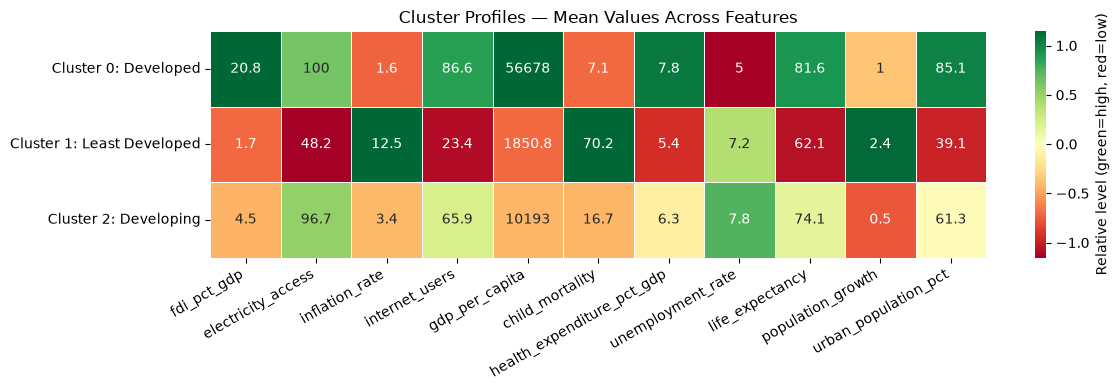

In [96]:
profile_norm = profile[feature_cols].copy()
profile_norm = (profile_norm - profile_norm.mean()) / profile_norm.std()
profile_norm.index = ["Cluster 0: Developed", "Cluster 1: Least Developed", "Cluster 2: Developing"]

plt.figure(figsize=(12, 4))
sns.heatmap(
    profile_norm,
    annot=profile[feature_cols].round(1),
    fmt="g",
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "Relative level (green=high, red=low)"}
)
plt.title("Cluster Profiles — Mean Values Across Features")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("cluster_heatmap.png", dpi=150)
plt.show()

## 4. Key Findings and Insights

### 4.1 Three Distinct Development Tiers

K-Means clustering with k=3 identified three well-differentiated country groups:

| Feature | Cluster 0: Developed (49) | Cluster 1: Least Developed (50) | Cluster 2: Developing (118) |
|---|---|---|---|
| GDP per capita (USD) | 56,678 | 1,851 | 10,193 |
| Life expectancy (years) | 81.6 | 62.1 | 74.1 |
| Child mortality (per 1,000) | 7.1 | 70.2 | 16.7 |
| Electricity access (%) | 100.0 | 48.2 | 96.7 |
| Internet users (%) | 86.6 | 23.4 | 65.9 |
| Inflation rate (%) | 1.6 | 12.5 | 3.4 |
| Population growth (%) | 0.96 | 2.45 | 0.54 |

The separation between clusters is sharp and consistent across multiple dimensions simultaneously — not just income, but health outcomes, infrastructure access, and demographic pressure. This multi-dimensional coherence validates the clustering approach over simple income-based classification.

### 4.2 PCA Reveals a Single Dominant Development Axis

PC1 alone explains 41.7% of all variance across 11 indicators. Its loadings reveal it is a composite human development score — strongly positively weighted on internet access (0.430), life expectancy (0.430), and electricity access (0.405), and strongly negatively weighted on child mortality (-0.408) and population growth (-0.267). The fact that one axis captures so much variance confirms that global development is fundamentally unidimensional — countries advance or fall behind across all these dimensions together, not independently.

PC2 (11.1%) captures economic volatility — separating high-unemployment, high-health-spending countries from high-FDI, high-growth ones. PC3 (9.4%) captures investment openness, driven primarily by FDI as a share of GDP.

Together, six components explain 86.2% of all variance, meaning the 11-indicator dataset can be compressed to roughly half its dimensionality with minimal information loss.

### 4.3 DBSCAN Identifies Structurally Anomalous Countries

Rather than finding clusters, DBSCAN identified 22 outlier countries that do not conform to any dense neighbourhood in the feature space. These include:

- **Liechtenstein and Monaco** — extreme GDP outliers ($166k and $193k per capita respectively) due to their status as wealthy microstates
- **Luxembourg** — similarly anomalous high income relative to size
- **Central African Republic** — child mortality of 254 per 1,000, the highest in the dataset by a wide margin
- **Argentina** — mid-level income but anomalously high inflation, reflecting structural economic instability
- **North Korea** — unusual socioeconomic profile resulting from political isolation

These outliers are not noise in the statistical sense — each has a coherent real-world explanation. DBSCAN's value here was in surfacing countries that warrant individual attention rather than being grouped with their geographic or income-level peers.

### 4.4 Practical Implications

The three-cluster structure has direct implications for international development policy. The 50 countries in Cluster 1 share a common profile of low electricity access, high child mortality, high inflation, and rapid population growth — suggesting that infrastructure investment, healthcare access, and monetary stability should be prioritised simultaneously rather than sequentially. The 118 countries in Cluster 2 represent a highly heterogeneous middle tier where targeted interventions based on each country's specific weaknesses would be more effective than blanket development programmes.

## 5. Limitations and Future Work

### 5.1 Limitations

**Single year snapshot**  
The analysis uses 2019 data exclusively. Development trajectories matter as much as current status — a country growing rapidly may belong in a different cluster in five years. A single cross-section cannot capture momentum, regression, or structural change over time.

**Median imputation**  
Missing values were filled with column medians. While this preserves country coverage, it compresses the true distribution for countries with sparse data — particularly smaller island nations and conflict-affected states where data collection is limited. These countries may be assigned to clusters that do not accurately reflect their true development profile.

**Indicator selection bias**  
The 11 indicators were selected based on availability and coverage in 2019. Important dimensions of development are absent — governance quality, gender equality, environmental sustainability, and social cohesion. The clusters reflect what was measured, not necessarily the full picture of development.

**K-Means assumptions**  
K-Means assumes spherical, equally sized clusters and is sensitive to outliers. The presence of extreme outliers like Monaco and Liechtenstein pulls cluster centroids, particularly for Cluster 0. The modest silhouette scores (0.19–0.24) confirm that the clusters are not perfectly compact — they are analytically useful partitions of a continuous space rather than truly discrete groups.

**DBSCAN sensitivity**  
DBSCAN results are highly sensitive to the epsilon and min_samples hyperparameters, and no principled automated method was used to select them. A more rigorous approach would use the k-distance graph to identify the optimal epsilon value systematically.

### 5.2 Future Work

**Longitudinal clustering**  
Extending the analysis to cover multiple years (e.g. 2000, 2010, 2019) would allow tracking of how countries move between clusters over time — identifying which nations are on upward trajectories and which are stagnating or regressing.

**Richer indicator set**  
Incorporating governance indicators (World Governance Indicators), environmental data (CO2 per capita, forest cover), and gender indices (GII, GDI) would produce a more complete representation of development and likely reveal sub-clusters within the current Cluster 2 middle tier.

**Hierarchical clustering**  
Agglomerative hierarchical clustering would produce a dendrogram showing the full tree of country relationships, allowing analysts to choose the level of granularity that suits their purpose rather than committing to a fixed k.

**Per-cluster predictive modelling**  
A natural extension of this work is to train separate supervised models within each cluster — for example, predicting GDP growth or human development index trajectories — and compare performance against a single global model. The hypothesis is that within-cluster homogeneity would reduce model error relative to a one-size-fits-all approach.

**Addressing outliers explicitly**  
Microstates and extreme outliers could be modelled separately or excluded from clustering, then re-assigned post-hoc based on nearest centroid distance. This would prevent them from distorting cluster centroids while still assigning them a meaningful group membership.